In [1]:
import numpy as np

In [2]:
import pandas as pd

In [10]:
import numpy as np


def sigmoid(x):
    return 1 / (1 + np.exp(-x))


class SimpleNeuralNetwork:
    """A simple neural network with one hidden layer."""

    def __init__(self, input_size, hidden_size, output_size):
        self.w1 = np.random.rand(input_size, hidden_size) * 0.5
        self.b1 = np.zeros((1, hidden_size))
        self.w2 = np.random.rand(hidden_size, output_size) * 0.5
        self.b2 = np.zeros((1, output_size))
        self.loss_history = []

    def forward(self, X):
        self.z1 = np.dot(X, self.w1) + self.b1
        self.a1 = sigmoid(self.z1)
        self.z2 = np.dot(self.a1, self.w2) + self.b2
        self.a2 = sigmoid(self.z2)
        return self.a2

    def backward(self, X, y, output, learning_rate=0.1):
        m = X.shape[0]

        dz2 = (output - y) * output * (1 - output)
        dw2 = np.dot(self.a1.T, dz2) / m
        db2 = np.sum(dz2, axis=0, keepdims=True) / m

        da1 = np.dot(dz2, self.w2.T)
        dz1 = da1 * self.a1 * (1 - self.a1)
        dw1 = np.dot(X.T, dz1) / m
        db1 = np.sum(dz1, axis=0, keepdims=True) / m

        self.w2 -= learning_rate * dw2
        self.b2 -= learning_rate * db2
        self.w1 -= learning_rate * dw1
        self.b1 -= learning_rate * db1

    def train(self, X, y, epochs=1000, learning_rate=0.1):
        for epoch in range(epochs):
            output = self.forward(X)
            loss = np.mean((output - y) ** 2)
            self.loss_history.append(loss)
            self.backward(X, y, output, learning_rate)

            if epoch % 100 == 0:
                print(f"Epoch {epoch}, Loss: {loss:.4f}")

    def predict(self, X):
        return self.forward(X)


# Create training data
np.random.seed(42)
X_train = np.random.rand(100, 4)
y_train = (
    (X_train[:, 0] > 0.7) & (X_train[:, 2] > 0.5)
).astype(float).reshape(-1, 1)
y_train += np.random.rand(100, 1) * 0.2
y_train = np.clip(y_train, 0, 1)

# Create and train the network
nn = SimpleNeuralNetwork(input_size=4, hidden_size=8, output_size=1)
print("Training neural network...\n")
nn.train(X_train, y_train, epochs=500, learning_rate=0.5)


    


Training neural network...

Epoch 0, Loss: 0.4314
Epoch 100, Loss: 0.1226
Epoch 200, Loss: 0.1219
Epoch 300, Loss: 0.1211
Epoch 400, Loss: 0.1203


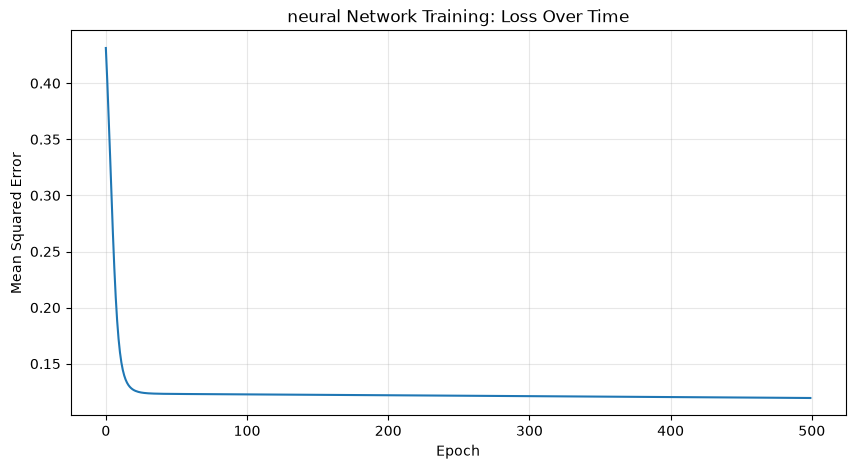


Final loss:0.1194


In [18]:
# Visualize training progress
plt.figure(figsize=(10, 5))
plt.plot(nn.loss_history)
plt.title('neural Network Training: Loss Over Time')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error')
plt.grid(True, alpha=0.3)
plt.show()

print(f"\nFinal loss:{nn.loss_history[-1]:.4f}")

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
import pandas as pd
# Set random seed for reproducibility
np.random.seed

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [20]:
# Your Code Here
# Normalize inputs (scale to 0-1 range)
def normalize_input(day, time, weather, mood):
    return np.array([[day/7, time/24, weather, mood]])

#WTest scenarios
scenarios = [
    ("Weekend evening, good weather", 6, 18, 0.8, 0.9),
    ("Weekend morning, poor weather", 2, 8, 0.3, 0.5),
    ("Weekend afternoon, bad Weather", 5, 14, 0.2, 0.6),
]

# Make predictions and analyse
for name, day, time, weather, mood in scenarios:
    X_test = normalize_input(day, time, weather, mood)
    prediction = nn.predict(X_test)
    print(f"{name}")
    print(f" social activity probability: {prediction[0][0]:.2%}\n")

Weekend evening, good weather
 social activity probability: 28.55%

Weekend morning, poor weather
 social activity probability: 27.44%

Weekend afternoon, bad Weather
 social activity probability: 28.10%



Given text: I love coding in python because it is

Predicted next word probabilities:
 fun: 24.89%
 simple: 21.44%
 elegant: 19.99%
 clear: 17.61%
 easy: 11.45%
 power: 3.80%
 versatile: 0.82%


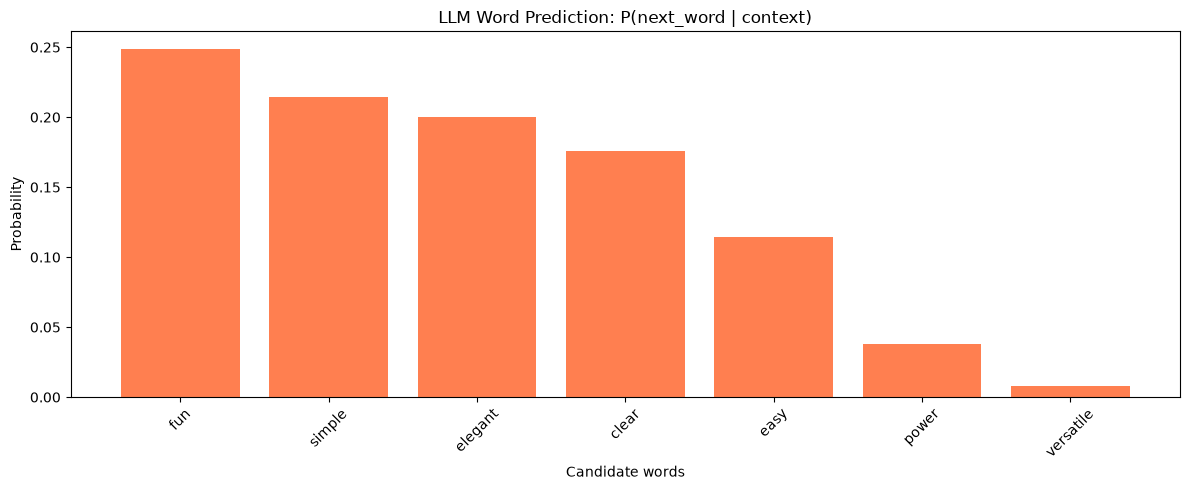

In [24]:
# Simple word prediction example
text_sequence = "I love coding in python because it is"
words = text_sequence.split()

# Simulate word prediction
word_vocab = ['fun', 'easy', 'power', 'versatile', 'simple', 'clear', 'elegant']
word_probs = np.random.rand(len(word_vocab))
word_probs = word_probs / word_probs.sum() # Normalize to probabilities

# Create probability distribution
word_dist = dict(zip(word_vocab, word_probs))
word_dist = dict(sorted(word_dist.items(), key=lambda x: x[1], reverse=True))

print("Given text:", text_sequence)
print("\nPredicted next word probabilities:")
for word, prob in word_dist.items():
    print(f" {word}: {prob:.2%}")

#Visualize
plt.figure(figsize=(12, 5))
plt.bar(word_dist.keys(), word_dist.values(), color='coral')
plt.title('LLM Word Prediction: P(next_word | context)')
plt.ylabel('Probability')
plt.xlabel('Candidate words')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()